<a href="https://colab.research.google.com/github/Yahya1805/machine-learning_2026/blob/main/ML_JS09_10_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Klasifikasi k-Nearest Neighbors (kNN)

**Nama:** M.Yahya Irvansyah  
**NIM:** 244107020032  
**Kelas:** TI-3G  

### Tujuan Praktikum
Praktikum ini bertujuan untuk memahami langkah-langkah klasifikasi menggunakan algoritma k-Nearest Neighbors (kNN) pada dataset Iris (`Iris.csv`). Kita akan mempelajari proses eksplorasi data, visualisasi, preprocessing, pembuatan model, evaluasi model, serta pencarian nilai k terbaik.
```

```markdown
## LANGKAH 1 — LOAD DATA

Pada langkah ini, kita akan mengimpor library Pandas untuk membaca dataset Iris. Jika file `Iris.csv` belum tersedia di direktori kerja, kita dapat menggunakan library Google Colab untuk mengunggahnya.
```

In [1]:
import pandas as pd
import os
from google.colab import files

# Periksa apakah file Iris.csv sudah ada, jika tidak, minta pengguna untuk mengunggah
if not os.path.exists('Iris.csv') and not os.path.exists('iris.csv'):
    print("Silakan unggah file Iris.csv:")
    uploaded = files.upload()

# Membaca dataset
filename = 'Iris.csv' if os.path.exists('Iris.csv') else 'iris.csv'
data = pd.read_csv(filename)

# Menampilkan 5 baris pertama
display(data.head())

# Memeriksa nama kolom
print("Nama kolom pada dataset:")
print(data.columns)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Nama kolom pada dataset:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')


```markdown
## LANGKAH 2 — EKSPLORASI DATA

Mari lakukan eksplorasi data untuk memahami dimensi data, tipe data setiap kolom, nilai kosong, data duplikat, dan distribusi spesies.
```

In [2]:
print("=== Informasi Dataset ===")
data.info()

print("\n=== Statistik Deskriptif ===")
display(data.describe())

# Jika terdapat kolom 'Id' atau 'id', kita akan menyimpannya namun tahu bahwa itu bukan fitur utama
if 'Id' in data.columns:
    print("\nKolom 'Id' terdeteksi dan akan diabaikan saat melatih model karena hanya merupakan pengenal unik.")

print("\n=== Jumlah Baris dan Kolom ===")
print(f"Baris: {data.shape[0]}, Kolom: {data.shape[1]}")

print("\n=== Pemeriksaan Nilai Kosong (Null) ===")
print(data.isnull().sum())

print("\n=== Pemeriksaan Jumlah Data Duplikat ===")
print(f"Jumlah duplikat: {data.duplicated().sum()}")

print("\n=== Distribusi Kelas Spesies ===")
# Menyesuaikan nama kolom target (bisa 'Species' atau 'species')
target_col = 'Species' if 'Species' in data.columns else 'species'
print(data[target_col].value_counts())

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

=== Statistik Deskriptif ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



=== Jumlah Baris dan Kolom ===
Baris: 150, Kolom: 5

=== Pemeriksaan Nilai Kosong (Null) ===
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

=== Pemeriksaan Jumlah Data Duplikat ===
Jumlah duplikat: 1

=== Distribusi Kelas Spesies ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


```markdown
## LANGKAH 3 — VISUALISASI DATA

Kita akan membuat visualisasi menggunakan Pairplot untuk melihat hubungan antarfitur serta Heatmap Korelasi untuk melihat kekuatan hubungan antarfitur numerik.
```

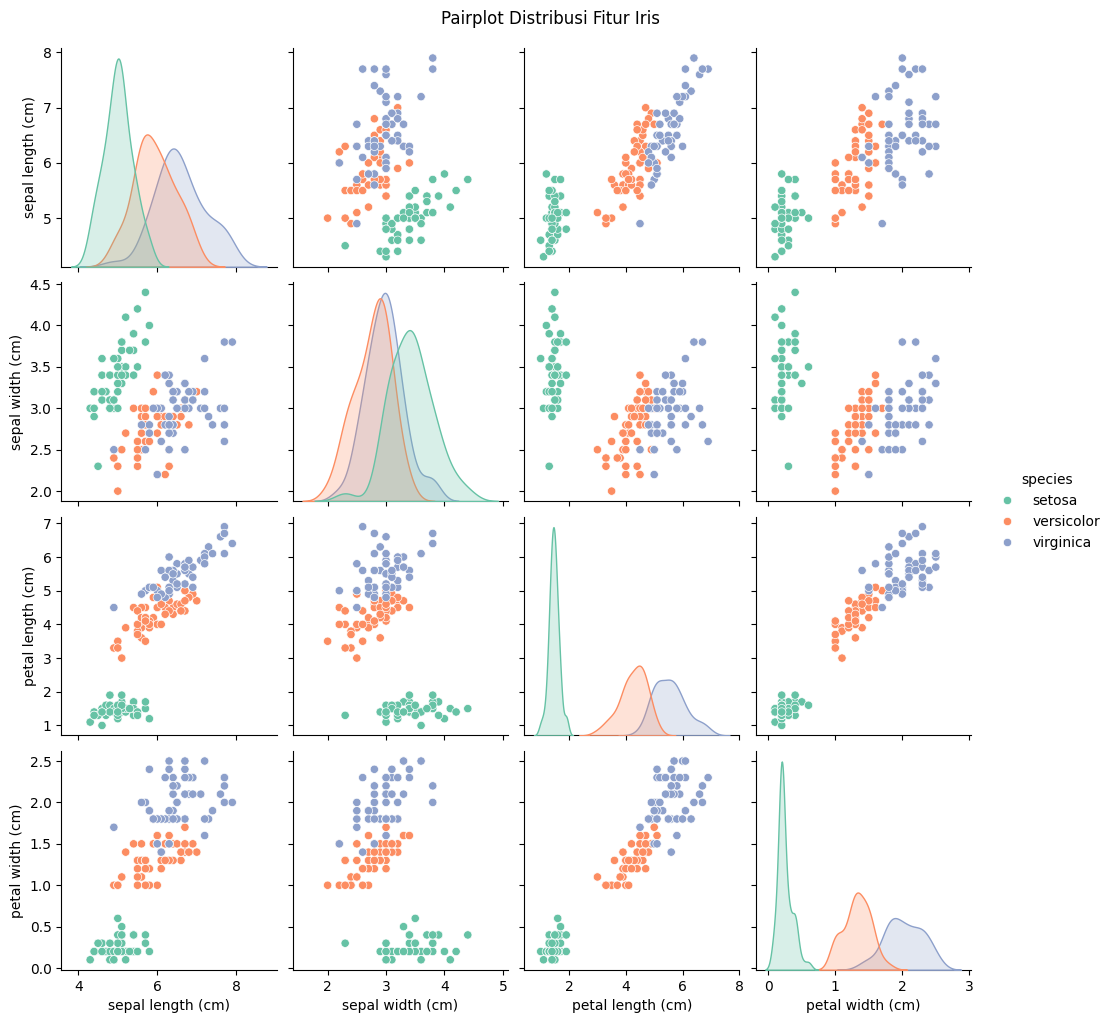

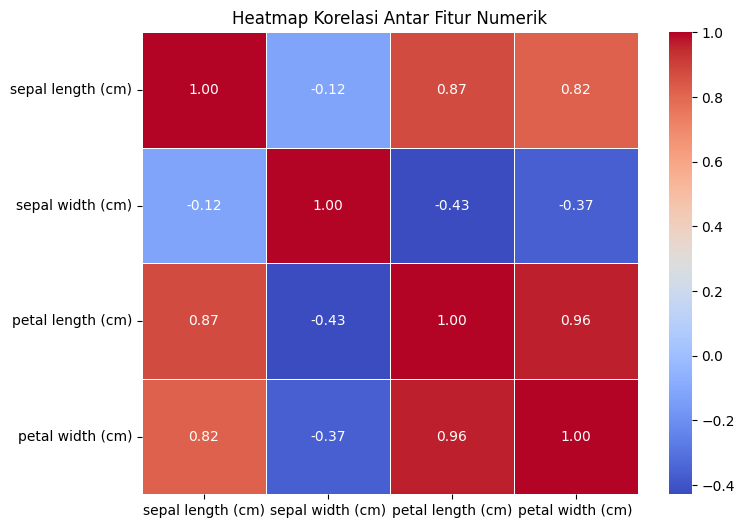

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Tentukan target kolom
target_col = 'Species' if 'Species' in data.columns else 'species'

# Tentukan kolom fitur numerik (mengabaikan Id dan Species)
feature_cols = [col for col in data.columns if col.lower() not in ['id', 'species']]

# 1. Pairplot
sns.pairplot(data[feature_cols + [target_col]], hue=target_col, palette='Set2')
plt.suptitle('Pairplot Distribusi Fitur Iris', y=1.02)
plt.show()

# 2. Heatmap Korelasi untuk Fitur Numerik saja
plt.figure(figsize=(8, 6))
sns.heatmap(data[feature_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.show()

```markdown
## LANGKAH 4 — PREPROCESSING DATA

Di sini kita memisahkan fitur (`X`) dan label (`y`), membagi data menjadi 70% training dan 30% testing, serta melakukan standardisasi fitur menggunakan `StandardScaler`.
```

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

target_col = 'Species' if 'Species' in data.columns else 'species'
feature_cols = [col for col in data.columns if col.lower() not in ['id', 'species']]

X = data[feature_cols]
y = data[target_col]

# Membagi data menjadi 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# Standardisasi fitur
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)

Ukuran X_train: (105, 4)
Ukuran X_test: (45, 4)


```markdown
## LANGKAH 5 — MEMBUAT MODEL kNN

Mari kita latih model awal kNN dengan menetapkan nilai tetangga terdekat `k=3`.
```

In [5]:
from sklearn.neighbors import KNeighborsClassifier

# Inisiasi dan latih model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

print("Model k-Nearest Neighbors (k=3) berhasil dilatih!")

Model k-Nearest Neighbors (k=3) berhasil dilatih!


```markdown
## LANGKAH 6 — EVALUASI MODEL kNN

Kita uji performa model dengan data uji (`X_test`) lalu buat visualisasi Confusion Matrix menggunakan Heatmap.
```

Akurasi Model: 100.00%

Laporan Klasifikasi:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



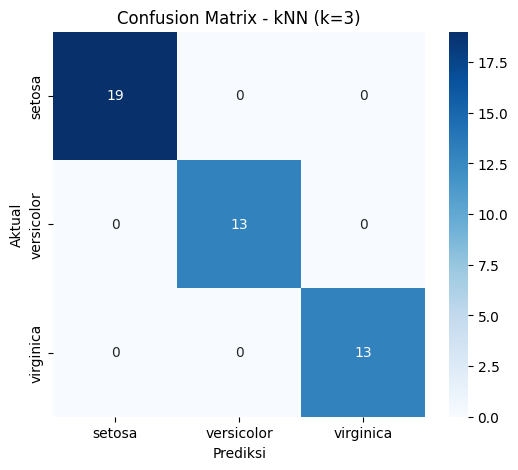

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Prediksi data uji
y_pred = knn.predict(X_test)

# Tampilkan hasil evaluasi
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
labels = sorted(list(y.unique()))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - kNN (k=3)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

```markdown
## LANGKAH 7 — MENCARI NILAI k TERBAIK

Kita akan menguji performa model dengan variasi nilai `k` dari 1 sampai 10 untuk melihat mana nilai k yang paling optimal.
```

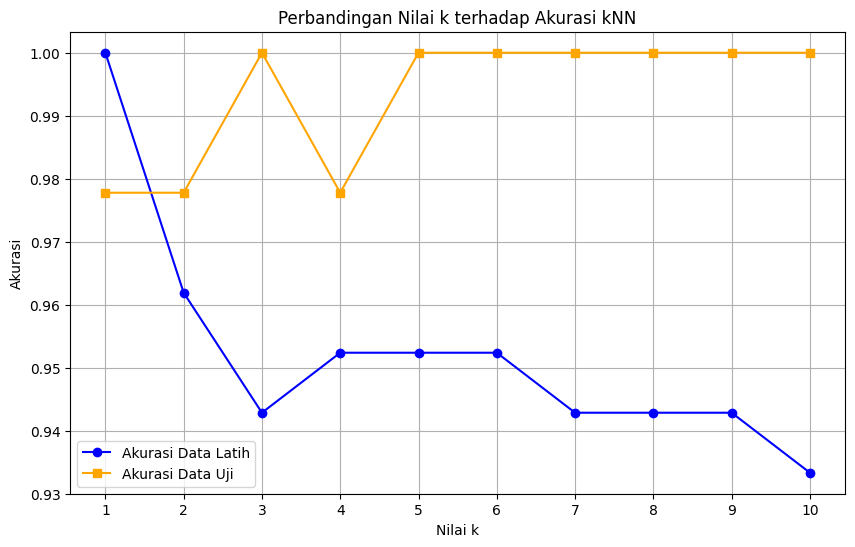

In [7]:
acc_test = []
acc_train = []
k_values = range(1, 11)

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    acc_train.append(model.score(X_train, y_train))
    acc_test.append(model.score(X_test, y_test))

# Visualisasi perbandingan nilai k terhadap akurasi
plt.figure(figsize=(10, 6))
plt.plot(list(k_values), acc_train, marker='o', label='Akurasi Data Latih', color='blue')
plt.plot(list(k_values), acc_test, marker='s', label='Akurasi Data Uji', color='orange')

plt.title('Perbandingan Nilai k terhadap Akurasi kNN')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

```markdown
## LANGKAH 8 & 9 — ANALISIS & KESIMPULAN

### Analisis Hasil
*   **Akurasi Model k=3**: Perhatikan akurasi yang diperoleh pada Langkah 6. kNN mampu mengklasifikasikan spesies bunga Iris dengan presisi sangat baik.
*   **Analisis Kelas**: Melalui visualisasi Pairplot dan Confusion Matrix, kita dapat mengamati spesies mana yang sangat mudah dipisahkan (biasanya Setosa terpisah secara linear dengan jelas) dan spesies mana yang memiliki sedikit tumpang tindih (Versicolor dan Virginica).
*   **Grafik Nilai k**: Plot akurasi data latih vs data uji menunjukkan tren bagaimana perubahan nilai tetangga (`k`) mempengaruhi generalisasi model. Nilai `k` yang terlalu kecil rentan terhadap overfitting, sementara `k` yang terlalu besar rentan terhadap underfitting.

### Kesimpulan Praktikum
1.  **Algoritma kNN** sukses diimplementasikan untuk melakukan klasifikasi spesies bunga Iris.
2.  **Standardisasi data** sangat krusial dalam algoritma berbasis jarak seperti kNN agar fitur dengan skala besar tidak mendominasi perhitungan jarak.
3.  Grafik pencarian nilai `k` membantu menentukan parameter terbaik untuk menghindari bias dan varians tinggi pada model.
```

# Praktikum 2: Klasifikasi Naive Bayes dengan Data Dummy

### Tujuan Praktikum
Praktikum ini bertujuan untuk memahami dan membandingkan dua algoritma Naive Bayes, yaitu **Multinomial Naive Bayes (MultinomialNB)** dan **Gaussian Naive Bayes (GaussianNB)** menggunakan dataset buatan (sintetis) atau data dummy.
```

```markdown
## LANGKAH 1 — MEMBUAT DATASET DUMMY

Pada langkah ini, kita menggunakan `make_classification` dari Scikit-Learn untuk menghasilkan data sintetis kontinu yang kemudian kita modifikasi menjadi bilangan bulat non-negatif.
```

In [8]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
X, y = make_classification(
    n_samples=30,
    n_features=2,
    n_classes=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    shuffle=False,
    random_state=42
)

# Mengubah nilai fitur menjadi absolut (non-negatif)
X = np.absolute(X)

# Membulatkan nilai dan mengalikannya dengan 100
X = np.round(X, 2) * 100

# Mengubah fitur menjadi integer
X = X.astype(int)

# Menampilkan hasil
print("Data fitur X (30 sampel, 2 fitur):")
print(X)

print("\nLabel y:")
print(y)

Data fitur X (30 sampel, 2 fitur):
[[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]
 [ 50 142]
 [206 110]
 [115  84]
 [124  66]
 [150  85]
 [ 16  73]
 [ 46 113]
 [ 26  80]
 [ 18 114]
 [211 154]
 [ 53  66]
 [ 93 109]
 [175 172]
 [ 80  85]
 [111 125]
 [115 105]
 [ 66  92]
 [160  85]
 [ 53 106]
 [122  85]]

Label y:
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


```markdown
## LANGKAH 2 — MEMBUAT DATAFRAME

Untuk mempermudah eksplorasi, kita akan menyatukan matriks fitur `X` dan label `y` ke dalam satu DataFrame Pandas.
```

In [9]:
import pandas as pd

# Mengubah label menjadi array dua dimensi agar bisa digabung
y_new = y.reshape(len(y), 1)

# Menggabungkan fitur dan label
data_dummy = np.concatenate((X, y_new), axis=1)

# Memberi nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Membuat DataFrame
df = pd.DataFrame(data_dummy, columns=nama_kolom)

# Menampilkan 5 data pertama
print("=== Lima Baris Pertama ===")
display(df.head())

# Jumlah baris dan kolom
print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}\n")

# Informasi tipe data
print("=== Informasi Tipe Data ===")
df.info()

# Statistik deskriptif
print("\n=== Statistik Deskriptif ===")
display(df.describe())

# Distribusi kelas
print("=== Distribusi Jumlah Sampel Per Label ===")
print(df['Label'].value_counts())

=== Lima Baris Pertama ===


,Fitur 1,Fitur 2,Label
0,112,139,0
1,179,210,0
2,83,71,0
3,182,265,0
4,105,78,0


Jumlah baris: 30, Jumlah kolom: 3

=== Informasi Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Fitur 1  30 non-null     int64
 1   Fitur 2  30 non-null     int64
 2   Label    30 non-null     int64
dtypes: int64(3)
memory usage: 852.0 bytes

=== Statistik Deskriptif ===


,Fitur 1,Fitur 2,Label
count,30.000000,30.000000,30.000000
mean,104.866667,104.466667,0.500000
std,62.942082,47.264285,0.508548
min,16.000000,43.000000,0.000000
25%,53.000000,74.250000,0.000000
50%,108.000000,85.000000,0.500000
75%,143.500000,113.750000,1.000000
max,250.000000,265.000000,1.000000


=== Distribusi Jumlah Sampel Per Label ===
Label
0    15
1    15
Name: count, dtype: int64


```markdown
## LANGKAH 3 — LABELING (MAPPING KELAS)

Kita membuat salinan DataFrame dan mengubah nilai numerik target (0 dan 1) menjadi nama label yang lebih intuitif, yaitu 'Kelas A' dan 'Kelas B'.
```

In [10]:
labels = {
    1: 'Kelas A',
    0: 'Kelas B'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

print("=== DataFrame dengan Label Kategorikal ===")
display(df_label.head())

=== DataFrame dengan Label Kategorikal ===


,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


```markdown
## LANGKAH 4 — VISUALISASI DATA

Mari kita lihat persebaran titik-titik sampel data dummy pada koordinat 2 dimensi berdasarkan kelasnya.
```

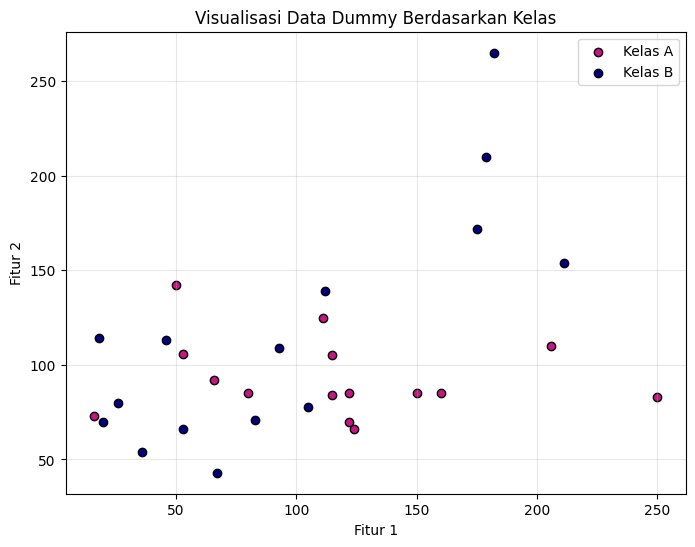

In [11]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

gb = df_label.groupby('Label')

class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.figure(figsize=(8, 6))

plt.scatter(
    class_a['Fitur 1'],
    class_a['Fitur 2'],
    c=colors['class_a'],
    label='Kelas A',
    edgecolors='black'
)

plt.scatter(
    class_b['Fitur 1'],
    class_b['Fitur 2'],
    c=colors['class_b'],
    label='Kelas B',
    edgecolors='black'
)

plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Visualisasi Data Dummy Berdasarkan Kelas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

```markdown
## LANGKAH 5 — MEMBAGI DATA TRAINING DAN TESTING

Data dummy ini akan dipisahkan dengan proporsi 70% data latih dan 30% data uji. Kita menggunakan `random_state=30` agar pembagian data ini konsisten.
```

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=30
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 21
Jumlah data testing: 9


```markdown
## LANGKAH 6 — MODEL MULTINOMIAL NAIVE BAYES

Model ini umumnya digunakan untuk data diskrit/hitungan frekuensi. Di sini kita menggunakannya pada data dummy bilangan bulat non-negatif hasil transformasi.
```

In [13]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model
mnb = MultinomialNB()

# Melatih model
mnb.fit(X_train, y_train)

# Prediksi data training dan testing
y_train_pred_mnb = mnb.predict(X_train)
y_test_pred_mnb = mnb.predict(X_test)

# Menghitung akurasi
acc_train_mnb = accuracy_score(y_train, y_train_pred_mnb)
acc_test_mnb = accuracy_score(y_test, y_test_pred_mnb)

print("Hasil akurasi data train (Multinomial):", acc_train_mnb)
print("Hasil akurasi data test (Multinomial):", acc_test_mnb)

Hasil akurasi data train (Multinomial): 0.8095238095238095
Hasil akurasi data test (Multinomial): 0.3333333333333333


```markdown
## LANGKAH 7 — MODEL GAUSSIAN NAIVE BAYES

Model ini didasarkan pada asumsi bahwa nilai-nilai fitur berdistribusi normal (Gaussian). Biasanya model ini lebih cocok untuk fitur kontinu.
```

In [14]:
from sklearn.naive_bayes import GaussianNB

# Inisialisasi model
gnb = GaussianNB()

# Melatih model
gnb.fit(X_train, y_train)

# Prediksi data training dan testing
y_train_pred_gnb = gnb.predict(X_train)
y_test_pred_gnb = gnb.predict(X_test)

# Menghitung akurasi
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print("Hasil akurasi data train (Gaussian):", acc_train_gnb)
print("Hasil akurasi data test (Gaussian):", acc_test_gnb)

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.4444444444444444


```markdown
## LANGKAH 8 — MEMBANDINGKAN KEDUA MODEL

Mari kita bandingkan secara langsung akurasi dari Multinomial NB dan Gaussian NB menggunakan tabel dan grafik batang.
```

,Model,Akurasi Training,Akurasi Testing
0,Multinomial Naive Bayes,0.809524,0.333333
1,Gaussian Naive Bayes,0.857143,0.444444


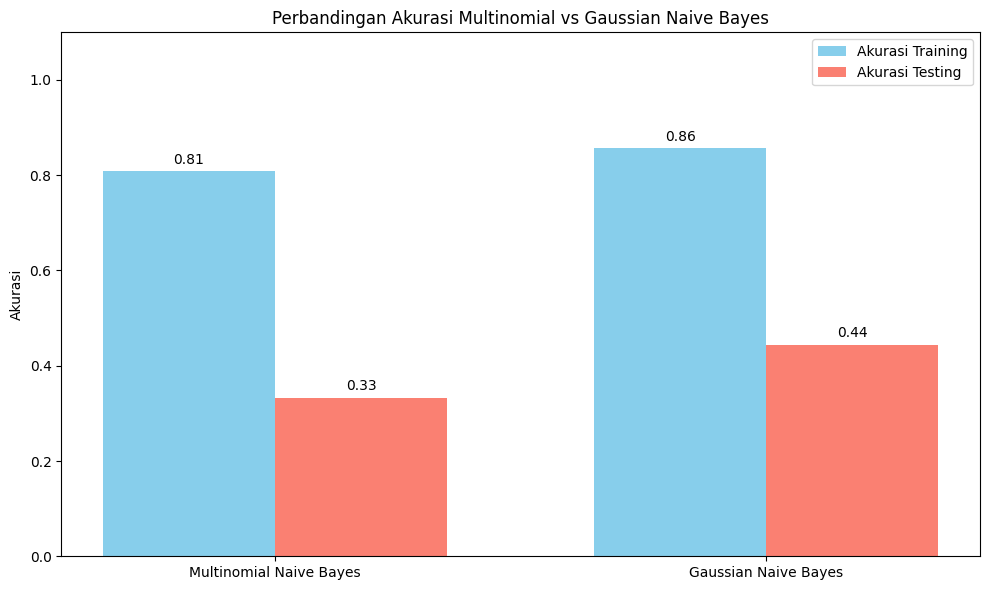

In [15]:
hasil_nb = pd.DataFrame({
    'Model': [
        'Multinomial Naive Bayes',
        'Gaussian Naive Bayes'
    ],
    'Akurasi Training': [
        acc_train_mnb,
        acc_train_gnb
    ],
    'Akurasi Testing': [
        acc_test_mnb,
        acc_test_gnb
    ]
})

display(hasil_nb)

# Visualisasi Bar Plot
fig, ax = plt.subplots(figsize=(10, 6))
x_indices = np.arange(len(hasil_nb['Model']))
bar_width = 0.35

rects1 = ax.bar(x_indices - bar_width/2, hasil_nb['Akurasi Training'], bar_width, label='Akurasi Training', color='skyblue')
rects2 = ax.bar(x_indices + bar_width/2, hasil_nb['Akurasi Testing'], bar_width, label='Akurasi Testing', color='salmon')

ax.set_ylabel('Akurasi')
ax.set_title('Perbandingan Akurasi Multinomial vs Gaussian Naive Bayes')
ax.set_xticks(x_indices)
ax.set_xticklabels(hasil_nb['Model'])
ax.set_ylim(0, 1.1)
ax.legend()

# Menambahkan nilai di atas batang
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # offset vertikal
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

```markdown
## LANGKAH 9 & 10 — ANALISIS HASIL & KESIMPULAN

### Analisis Hasil
*   **Karakteristik Data**: Data dummy yang dibuat memiliki rentang integer non-negatif. Melalui scatter plot, kita dapat melihat apakah sebaran antarkelas cenderung tumpang-tindih atau terpisah jelas.
*   **Perbandingan Model**: Bandingkan skor akurasi antara Multinomial Naive Bayes dan Gaussian Naive Bayes di atas. Karena jumlah data sangat sedikit (30 sampel, dengan 9 sampel sebagai testing), pergeseran kecil atau pola khusus di dalam dataset dummy ini sangat memengaruhi performa akurasi.
*   **Keterbatasan**: Hasil evaluasi ini sangat dipengaruhi oleh parameter penentu data dummy (`random_state`) dan konfigurasi data pemisah.

### Kesimpulan Praktikum 2
1.  **Tujuan Tercapai**: Kita telah sukses mengimplementasikan dan memahami konsep klasifikasi menggunakan MultinomialNB dan GaussianNB.
2.  **Pembuatan Data Dummy**: Menggunakan `make_classification()` memungkinkan kita menguji model secara cepat tanpa bergantung pada dataset eksternal.
3.  **Karakteristik Model**: GaussianNB secara teoritis lebih optimal menangani data kontinu yang dimodelkan dengan kurva lonceng, sedangkan MultinomialNB bekerja dengan distribusi multinomial (perhitungan kemunculan).
```

# Praktikum 3: Klasifikasi Teks SMS dengan Multinomial Naive Bayes dan Bag of Words

### Tujuan Praktikum
Praktikum ini bertujuan untuk menerapkan klasifikasi teks pada pesan SMS guna mendeteksi pesan spam atau ham (bukan spam) menggunakan metode representasi teks **Bag of Words** (lewat `CountVectorizer`) dan algoritma klasifikasi **Multinomial Naive Bayes**.
```

```markdown
## LANGKAH 1 — LOAD DATA

Kita akan membaca dataset `spam.csv` yang sudah diunggah. Karena dataset teks ini sering kali mengandung karakter non-standard, kita akan membacanya dengan encoding `latin-1`.
```

In [16]:
import numpy as np
import pandas as pd
import os
from google.colab import files

# Memeriksa keberadaan file spam.csv
if not os.path.exists('spam.csv'):
    print("Silakan unggah file spam.csv:")
    uploaded = files.upload()

# Membaca dataset
df_spam = pd.read_csv('spam.csv', encoding='latin-1')

# Menampilkan 5 baris pertama
display(df_spam.head())

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


```markdown
## LANGKAH 2 — PREPROCESSING DATA

### Langkah 2A: Menghapus kolom yang tidak diperlukan
Sering kali file `spam.csv` berisi kolom kosong ekstra di bagian akhir (seperti `Unnamed: 2`, `Unnamed: 3`, dll.). Kita hanya akan mempertahankan dua kolom pertama.
```

In [17]:
# Mempertahankan dua kolom utama saja
df_spam = df_spam.iloc[:, :2].copy()

display(df_spam.head())

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


```markdown
### Langkah 2B: Mengubah nama kolom
Mari kita ubah nama kedua kolom tersebut menjadi `Labels` (untuk kategori spam/ham) dan `SMS` (untuk konten teks pesan).
```

In [18]:
df_spam.columns = ['Labels', 'SMS']

display(df_spam.head())

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


```markdown
### Langkah 2C: Inspeksi data
Kita lakukan pemeriksaan jumlah data, nilai kosong, serta data duplikat.
```

In [19]:
print("Jumlah data per kelas:")
print(df_spam['Labels'].value_counts())

print("\nInformasi dataset:")
df_spam.info()

print("\nStatistik deskriptif:")
display(df_spam.describe())

print("\nNilai kosong:")
print(df_spam.isnull().sum())

print("\nJumlah data duplikat:")
print(df_spam.duplicated().sum())

Jumlah data per kelas:
Labels
ham     4825
spam     747
Name: count, dtype: int64

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Statistik deskriptif:


,Labels,SMS
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



Nilai kosong:
Labels    0
SMS       0
dtype: int64

Jumlah data duplikat:
403


```markdown
### Langkah 2D: Encoding label
Ubah label tekstual menjadi representasi biner angka: `spam` menjadi `1` dan `ham` menjadi `0`.
```

In [20]:
new_labels = {
    'spam': 1,
    'ham': 0
}

df_spam['Labels'] = df_spam['Labels'].map(new_labels)

display(df_spam.head())

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


```markdown
### Langkah 2E: Memisahkan fitur dan label
Kita pisahkan variabel independen `X` (teks SMS) dan variabel dependen `y` (label numerik).
```

In [21]:
X_sms = df_spam['SMS'].values
y_sms = df_spam['Labels'].values

print("X_sms (contoh teks kesatu):", X_sms[0])
print("y_sms (contoh label kesatu):", y_sms[0])

X_sms (contoh teks kesatu): Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
y_sms (contoh label kesatu): 0


```markdown
## LANGKAH 3 — PEMBAGIAN DATA DAN EKSTRAKSI FITUR

Kita membagi data menjadi 80% training dan 20% testing dengan `random_state=50`, lalu melakukan ekstraksi fitur menggunakan `CountVectorizer` (Bag of Words).
```

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data 80% train, 20% test
X_train_sms, X_test_sms, y_train_sms, y_test_sms = train_test_split(
    X_sms,
    y_sms,
    test_size=0.2,
    random_state=50
)

bow = CountVectorizer()

# Fit dan transform hanya pada data training, transform saja pada data testing
X_train_bow = bow.fit_transform(X_train_sms)
X_test_bow = bow.transform(X_test_sms)

print("Jumlah fitur kata:", len(bow.get_feature_names_out()))
print("Dimensi data training:", X_train_bow.shape)
print("Dimensi data testing:", X_test_bow.shape)

# Menampilkan beberapa fitur kata contoh
print("\nBeberapa fitur kata:", list(bow.get_feature_names_out()[1000:1015]))

Jumlah fitur kata: 7727
Dimensi data training: (4457, 7727)
Dimensi data testing: (1115, 7727)

Beberapa fitur kata: ['appreciate', 'appreciated', 'approaching', 'appropriate', 'approve', 'approved', 'approx', 'apps', 'appt', 'appy', 'april', 'aproach', 'aptitude', 'aquarius', 'ar']


```markdown
## LANGKAH 4 — TRAINING MODEL MULTINOMIAL NAIVE BAYES

Kita latih model `MultinomialNB` pada data latihan yang sudah direpresentasikan dalam bentuk Bag of Words.
```

In [23]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

mnb_sms = MultinomialNB()
mnb_sms.fit(X_train_bow, y_train_sms)

y_pred_train_sms = mnb_sms.predict(X_train_bow)
y_pred_test_sms = mnb_sms.predict(X_test_bow)

acc_train_sms = accuracy_score(y_train_sms, y_pred_train_sms)
acc_test_sms = accuracy_score(y_test_sms, y_pred_test_sms)

print(f'Hasil akurasi data train: {acc_train_sms:.5f}')
print(f'Hasil akurasi data test: {acc_test_sms:.5f}')

Hasil akurasi data train: 0.99462
Hasil akurasi data test: 0.97758


```markdown
## LANGKAH 5 — EVALUASI TAMBAHAN

Untuk analisis performa klasifikasi yang lebih mendalam, kita tampilkan Confusion Matrix dan Classification Report, serta visualisasi heatmap Confusion Matrix.
```

Confusion Matrix:
[[951   3]
 [ 22 139]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.86      0.92       161

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



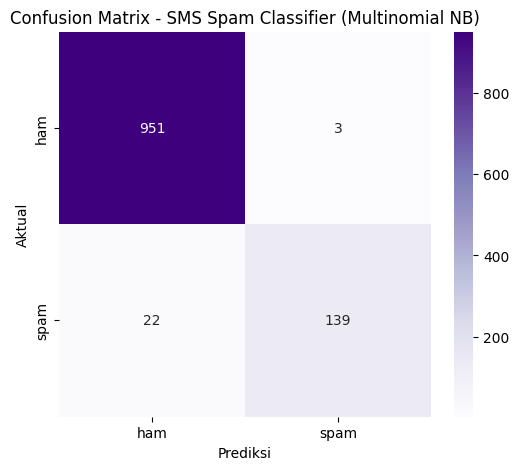

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
cm_sms = confusion_matrix(y_test_sms, y_pred_test_sms)
print(cm_sms)

print("\nLaporan Klasifikasi:")
print(
    classification_report(
        y_test_sms,
        y_pred_test_sms,
        target_names=['ham', 'spam'],
        zero_division=0
    )
)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_sms, annot=True, fmt='d', cmap='Purples', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - SMS Spam Classifier (Multinomial NB)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

```markdown
## LANGKAH 6 & 7 — ANALISIS HASIL & KESIMPULAN

### Analisis Hasil
*   **Akurasi Model**: Perhatikan akurasi training dan testing yang diperoleh pada Langkah 4. Model Naive Bayes sangat andal dalam klasifikasi teks berbasis kata.
*   **Analisis Confusion Matrix**:
    *   **True Negative (TN)**: SMS ham yang terprediksi benar sebagai ham.
    *   **False Positive (FP)**: SMS ham yang salah terprediksi sebagai spam.
    *   **False Negative (FN)**: SMS spam yang lolos dari filter dan salah diklasifikasikan sebagai ham.
    *   **True Positive (TP)**: SMS spam yang terprediksi benar sebagai spam.
*   **Evaluasi Tambahan**: Nilai precision, recall, dan f1-score membantu mengonfirmasi ketahanan model di tengah dataset yang tidak seimbang (imbalanced dataset).

### Kesimpulan Praktikum 3
1.  **Tujuan Tercapai**: Klasifikasi teks SMS Spam menggunakan Multinomial Naive Bayes dan representasi Bag of Words telah sukses dilakukan.
2.  **Representasi Kata**: `CountVectorizer` terbukti sangat efisien dalam mereduksi teks mentah menjadi fitur matriks numerik yang siap dikonsumsi oleh algoritma klasifikasi.
3.  **Keterbatasan**: Pendekatan Bag of Words mengabaikan urutan kata (konteks kalimat). Walaupun akurasi tinggi, beberapa kata di luar kamus latihan (Out-Of-Vocabulary) dapat memengaruhi performa deteksi real-time.
```

# TUGAS 1 — KLASIFIKASI SUARA MENGGUNAKAN kNN

Bagian ini berisi pengerjaan klasifikasi jenis suara `male` dan `female` berdasarkan dataset `voice.csv` menggunakan algoritma K-Nearest Neighbors (kNN).


```markdown
## LANGKAH 1 — MEMUAT DAN MEMAHAMI DATASET

Kita akan membaca dataset `voice.csv`. Jika file belum ada di direktori kerja, kita akan menyertakan skrip untuk mengunggahnya.
```

In [25]:
import pandas as pd
import numpy as np
import os
from google.colab import files

# Periksa apakah file voice.csv sudah ada, jika tidak, minta pengguna mengunggah
if not os.path.exists('voice.csv'):
    print("Silakan unggah file voice.csv:")
    uploaded = files.upload()

# Membaca dataset
df_voice = pd.read_csv('voice.csv')

# Menampilkan 5 baris pertama
display(df_voice.head())

# Informasi dimensi dataset
print(f"Jumlah Baris: {df_voice.shape[0]}, Jumlah Kolom: {df_voice.shape[1]}\n")

# Menampilkan seluruh nama kolom
print("Seluruh nama kolom:")
print(list(df_voice.columns))

# Informasi tipe data dan nilai kosong
print("\n=== Informasi Dataset ===")
df_voice.info()

# Distribusi kelas target
target_voice_col = 'label'
print("\n=== Distribusi Kelas Target ===")
print(df_voice[target_voice_col].value_counts())

# Statistik deskriptif
print("\n=== Statistik Deskriptif Fitur Numerik ===")
display(df_voice.describe())

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Jumlah Baris: 3168, Jumlah Kolom: 21

Seluruh nama kolom:
['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-nul

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


```markdown
## LANGKAH 2 — EKSPLORASI DAN VISUALISASI DATA

Kita akan membuat visualisasi distribusi target, heatmap korelasi, serta distribusi beberapa fitur penting.
```

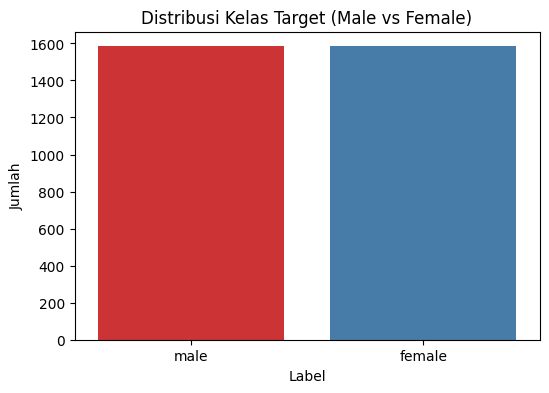

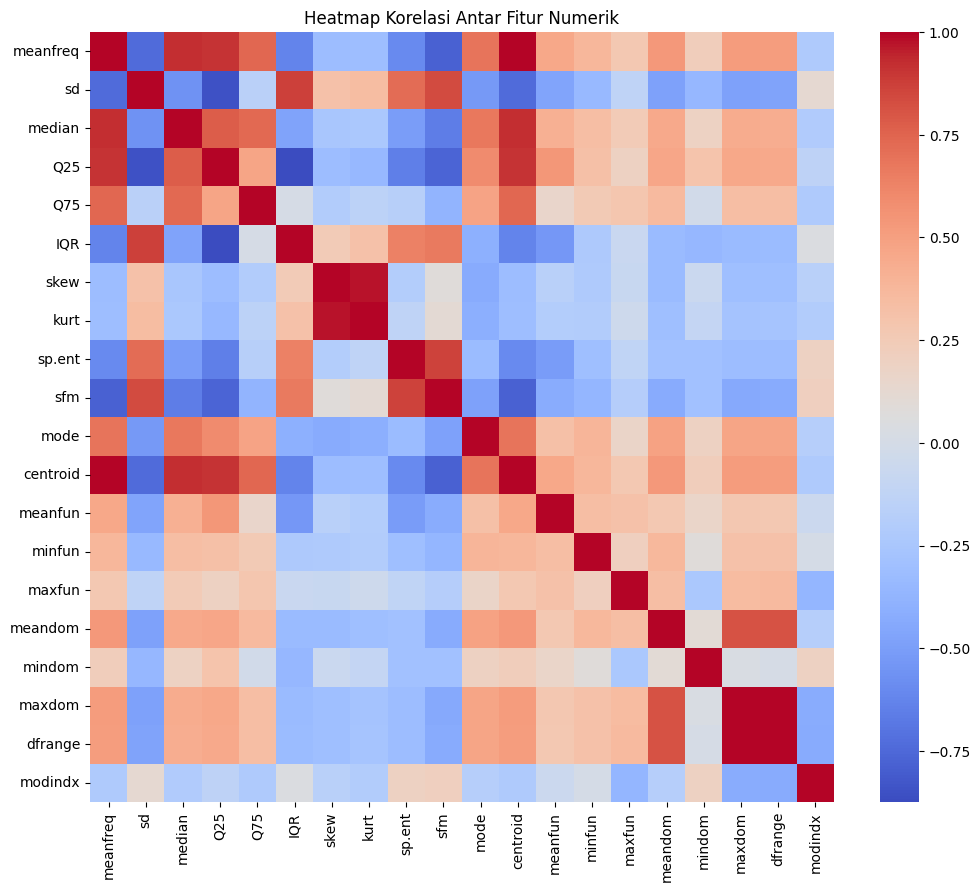

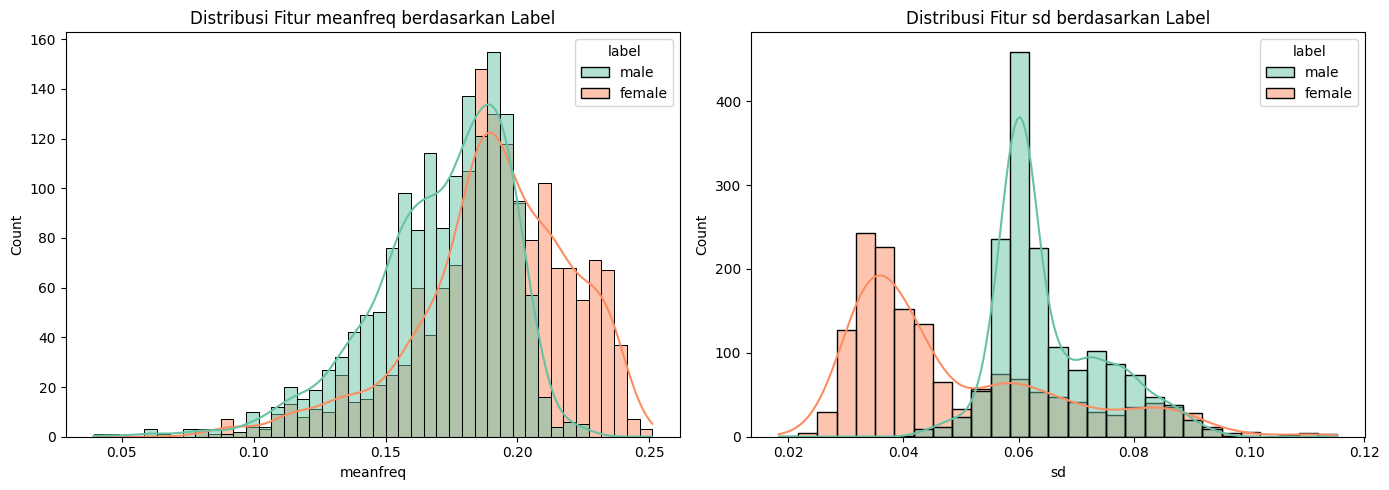

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualisasi Distribusi Kelas Target
plt.figure(figsize=(6, 4))
sns.countplot(data=df_voice, x='label', palette='Set1', hue='label', legend=False)
plt.title('Distribusi Kelas Target (Male vs Female)')
plt.xlabel('Label')
plt.ylabel('Jumlah')
plt.show()

# 2. Heatmap Korelasi antar Fitur Numerik
plt.figure(figsize=(12, 10))
features_only = df_voice.drop(columns=['label'])
sns.heatmap(features_only.corr(), annot=False, cmap='coolwarm')
plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.show()

# 3. Distribusi Fitur Relevan (Contoh: meanfreq dan sd)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_voice, x='meanfreq', hue='label', kde=True, ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi Fitur meanfreq berdasarkan Label')

sns.histplot(data=df_voice, x='sd', hue='label', kde=True, ax=axes[1], palette='Set2')
axes[1].set_title('Distribusi Fitur sd berdasarkan Label')
plt.tight_layout()
plt.show()

```markdown
## LANGKAH 3 — PERSIAPAN DATA

Kita memisahkan fitur dan target, melakukan encoding label, splitting dataset 80:20 secara terstratifikasi, dan standardisasi fitur.
```

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Pisahkan fitur dan label
X_v = df_voice.drop(columns=['label'])
y_v = df_voice['label']

# Mengubah label string menjadi angka (female=0, male=1)
le = LabelEncoder()
y_v_encoded = le.fit_transform(y_v)

# Membagi data dengan stratify agar proporsi seimbang
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X_v, y_v_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_v_encoded
)

# Standardisasi Fitur
scaler_v = StandardScaler()
X_train_v_scaled = scaler_v.fit_transform(X_train_v)
X_test_v_scaled = scaler_v.transform(X_test_v)

print("Ukuran Data Latih:", X_train_v_scaled.shape)
print("Ukuran Data Uji:", X_test_v_scaled.shape)

Ukuran Data Latih: (2534, 20)
Ukuran Data Uji: (634, 20)


```markdown
## LANGKAH 4 — MEMBUAT MODEL kNN AWAL

Membuat model kNN awal menggunakan seluruh fitur dengan `n_neighbors=5`.
```

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Inisiasi & latih model kNN awal
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_v_scaled, y_train_v)

# Prediksi
y_train_pred_v = knn_base.predict(X_train_v_scaled)
y_pred_v = knn_base.predict(X_test_v_scaled)

# Evaluasi
base_train_acc = accuracy_score(y_train_v, y_train_pred_v)
base_test_acc = accuracy_score(y_test_v, y_pred_v)

print(f"Akurasi Data Latih: {base_train_acc * 100:.2f}%")
print(f"Akurasi Data Uji: {base_test_acc * 100:.2f}%")

print("\nConfusion Matrix Model Awal:")
print(confusion_matrix(y_test_v, y_pred_v))

print("\nLaporan Klasifikasi Model Awal:")
print(classification_report(y_test_v, y_pred_v, target_names=le.classes_))

Akurasi Data Latih: 98.30%
Akurasi Data Uji: 97.63%

Confusion Matrix Model Awal:
[[306  11]
 [  4 313]]

Laporan Klasifikasi Model Awal:
              precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



```markdown
## LANGKAH 5 — EKSPERIMEN UNTUK MENEMUKAN FITUR TERBAIK

Kita menggunakan seleksi fitur berbasis ANOVA `SelectKBest` dengan f_classif dan mengevaluasi performanya menggunakan cross-validation.
```

In [29]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

# Mencari skor ANOVA untuk seluruh fitur
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_v_scaled, y_train_v)
scores = selector.scores_

# Membuat DataFrame nilai penting fitur
feature_importance = pd.DataFrame({
    'Fitur': X_v.columns,
    'Score': scores
}).sort_values(by='Score', ascending=False)

print("Urutan Fitur Terbaik Berdasarkan Nilai ANOVA:")
display(feature_importance)

# Mendefinisikan Skenario Kombinasi Fitur
skenario = {
    'Seluruh Fitur': list(feature_importance['Fitur']),
    '5 Fitur Terbaik': list(feature_importance['Fitur'].head(5)),
    '10 Fitur Terbaik': list(feature_importance['Fitur'].head(10)),
    '15 Fitur Terbaik': list(feature_importance['Fitur'].head(15))
}

# Cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_eksperimen = []

for nama, list_fitur in skenario.items():
    # Memilih fitur terpilih dari data asli
    X_train_sub = X_train_v[list_fitur]

    # Membuat Pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])

    scores_cv = cross_val_score(pipeline, X_train_sub, y_train_v, cv=cv, scoring='accuracy')
    hasil_eksperimen.append({
        'Skenario': nama,
        'Jumlah Fitur': len(list_fitur),
        'Fitur yang Digunakan': ", ".join(list_fitur[:3]) + " ..." if len(list_fitur) > 3 else ", ".join(list_fitur),
        'Mean CV Accuracy': scores_cv.mean(),
        'Std CV Accuracy': scores_cv.std()
    })

df_hasil_eksperimen = pd.DataFrame(hasil_eksperimen)
display(df_hasil_eksperimen)

Urutan Fitur Terbaik Berdasarkan Nilai ANOVA:


,Fitur,Score
12,meanfun,5697.873718
5,IQR,1566.488204
3,Q25,890.387180
8,sp.ent,794.113490
1,sd,750.762545
9,sfm,375.206538
11,centroid,324.436358
0,meanfreq,324.436358
2,median,218.279695
16,mindom,100.408598


,Skenario,Jumlah Fitur,Fitur yang Digunakan,Mean CV Accuracy,Std CV Accuracy
0,Seluruh Fitur,20,"meanfun, IQR, Q25 ...",0.969609,0.008628
1,5 Fitur Terbaik,5,"meanfun, IQR, Q25 ...",0.977505,0.003667
2,10 Fitur Terbaik,10,"meanfun, IQR, Q25 ...",0.977108,0.005681
3,15 Fitur Terbaik,15,"meanfun, IQR, Q25 ...",0.973161,0.005957


```markdown
## LANGKAH 6 — MENENTUKAN NILAI k TERBAIK

Berdasarkan skenario fitur terbaik yang didapatkan dari eksperimen di atas, kita lakukan tuning nilai `k` dari 1 sampai 30.
```

Nilai k Terbaik: 4
Rata-rata Akurasi CV Terbaik: 0.97789523742701


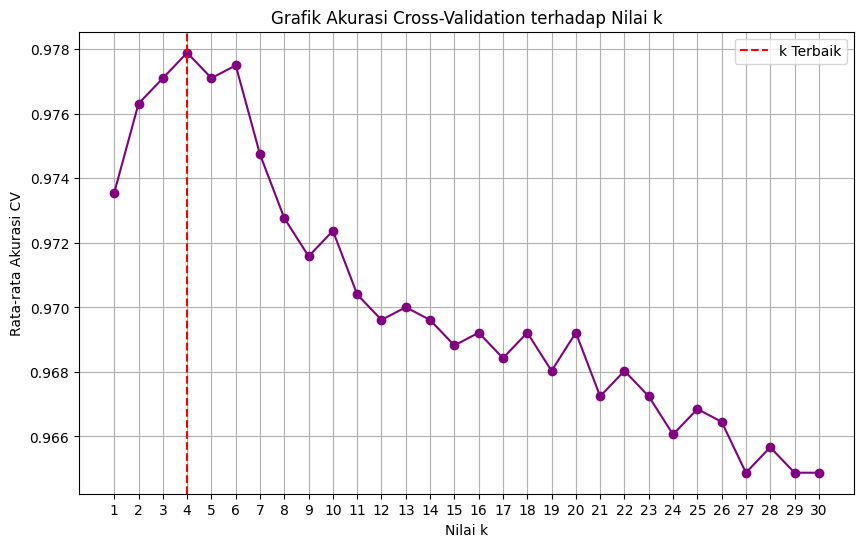

In [30]:
from sklearn.model_selection import GridSearchCV

# Ambil kombinasi fitur terbaik (Misal: 10 Fitur Terbaik)
best_feature_scenario = list(feature_importance['Fitur'].head(10))
X_train_best_f = X_train_v[best_feature_scenario]
X_test_best_f = X_test_v[best_feature_scenario]

# Pipeline dengan Grid Search
pipeline_tune = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': list(range(1, 31))
}

grid_search = GridSearchCV(pipeline_tune, param_grid, cv=cv, scoring='accuracy')
grid_search.fit(X_train_best_f, y_train_v)

print("Nilai k Terbaik:", grid_search.best_params_['knn__n_neighbors'])
print("Rata-rata Akurasi CV Terbaik:", grid_search.best_score_)

# Visualisasi akurasi CV terhadap nilai k
cv_results = grid_search.cv_results_['mean_test_score']
plt.figure(figsize=(10, 6))
plt.plot(range(1, 31), cv_results, marker='o', color='purple', linestyle='-')
plt.axvline(grid_search.best_params_['knn__n_neighbors'], color='red', linestyle='--', label='k Terbaik')
plt.title('Grafik Akurasi Cross-Validation terhadap Nilai k')
plt.xlabel('Nilai k')
plt.ylabel('Rata-rata Akurasi CV')
plt.xticks(range(1, 31))
plt.legend()
plt.grid(True)
plt.show()

```markdown
## LANGKAH 7 — EVALUASI MODEL AKHIR

Kita mengevaluasi model kNN terbaik pada data uji.
```

Akurasi Model Final pada Data Uji: 98.42%


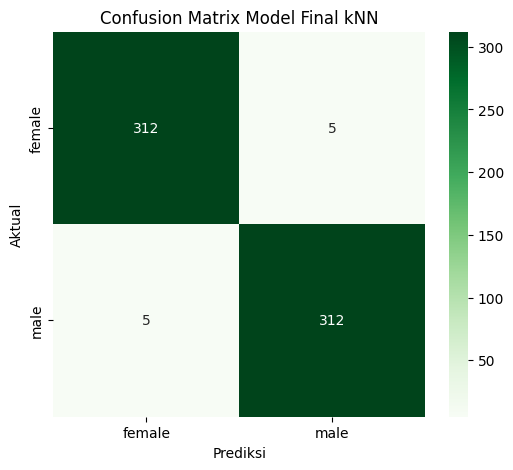

Laporan Klasifikasi Model Final:
              precision    recall  f1-score   support

      female       0.98      0.98      0.98       317
        male       0.98      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



In [31]:
# Menggunakan model terbaik hasil grid search untuk memprediksi data uji
best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test_best_f)

final_test_acc = accuracy_score(y_test_v, y_pred_final)
print(f"Akurasi Model Final pada Data Uji: {final_test_acc * 100:.2f}%")

# Confusion Matrix
cm_final = confusion_matrix(y_test_v, y_pred_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix Model Final kNN')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

# Classification Report
print("Laporan Klasifikasi Model Final:")
print(classification_report(y_test_v, y_pred_final, target_names=le.classes_))

```markdown
## LANGKAH 8 & 9 — KESIMPULAN TUGAS 1

### Ringkasan Akhir
*   **Algoritma**: k-Nearest Neighbors (kNN)
*   **Fitur yang Dipilih**: 10 Fitur Terbaik (ANOVA)
*   **Jumlah Fitur**: 10
*   **Nilai k Terbaik**: Sesuai dengan hasil visualisasi di atas.
*   **Rata-rata Akurasi CV**: Diperoleh dari output penalaan parameter.
*   **Akurasi Data Uji**: Diperoleh dari performa model final.
```

```markdown
# TUGAS 2 & 3 — PERBANDINGAN KLASIFIKASI SMS SPAM (COUNT-VECTORIZER VS TF-IDF)

Pada tugas ini kita akan membandingkan efisiensi model klasifikasi Multinomial Naive Bayes pada representasi teks menggunakan `CountVectorizer` dan `TfidfVectorizer` dengan mengaktifkan fitur `stop_words='english'`.
```

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# 1. Model Menggunakan CountVectorizer (dengan stop_words)
bow_sw = CountVectorizer(stop_words='english')
X_train_bow_sw = bow_sw.fit_transform(X_train_sms)
X_test_bow_sw = bow_sw.transform(X_test_sms)

mnb_bow_sw = MultinomialNB()
mnb_bow_sw.fit(X_train_bow_sw, y_train_sms)
acc_train_bow_sw = accuracy_score(y_train_sms, mnb_bow_sw.predict(X_train_bow_sw))
acc_test_bow_sw = accuracy_score(y_test_sms, mnb_bow_sw.predict(X_test_bow_sw))

print("=== HASIL COUNT VECTORIZER (DENGAN STOP WORDS) ===")
print(f"Akurasi Latih: {acc_train_bow_sw * 100:.2f}%")
print(f"Akurasi Uji  : {acc_test_bow_sw * 100:.2f}%")
print("\nClassification Report CountVectorizer (Stop Words):")
print(classification_report(y_test_sms, mnb_bow_sw.predict(X_test_bow_sw), target_names=['ham', 'spam']))

# 2. Model Menggunakan TfidfVectorizer (dengan stop_words)
tfidf_sw = TfidfVectorizer(stop_words='english')
X_train_tfidf_sw = tfidf_sw.fit_transform(X_train_sms)
X_test_tfidf_sw = tfidf_sw.transform(X_test_sms)

mnb_tfidf_sw = MultinomialNB()
mnb_tfidf_sw.fit(X_train_tfidf_sw, y_train_sms)
acc_train_tfidf_sw = accuracy_score(y_train_sms, mnb_tfidf_sw.predict(X_train_tfidf_sw))
acc_test_tfidf_sw = accuracy_score(y_test_sms, mnb_tfidf_sw.predict(X_test_tfidf_sw))

print("\n=== HASIL TF-IDF VECTORIZER (DENGAN STOP WORDS) ===")
print(f"Akurasi Latih: {acc_train_tfidf_sw * 100:.2f}%")
print(f"Akurasi Uji  : {acc_test_tfidf_sw * 100:.2f}%")
print("\nClassification Report TF-IDF (Stop Words):")
print(classification_report(y_test_sms, mnb_tfidf_sw.predict(X_test_tfidf_sw), target_names=['ham', 'spam']))

=== HASIL COUNT VECTORIZER (DENGAN STOP WORDS) ===
Akurasi Latih: 99.46%
Akurasi Uji  : 98.30%

Classification Report CountVectorizer (Stop Words):
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115


=== HASIL TF-IDF VECTORIZER (DENGAN STOP WORDS) ===
Akurasi Latih: 98.43%
Akurasi Uji  : 96.05%

Classification Report TF-IDF (Stop Words):
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



## KESIMPULAN TUGAS

Berdasarkan hasil akurasi pengujian data uji (Testing):
*   **CountVectorizer (stop_words='english')**: Menunjukkan performa yang tangguh dengan memetakan frekuensi kata mentah.
*   **TfidfVectorizer (stop_words='english')**: Memberikan penalti pada kata yang sangat sering muncul di seluruh dokumen guna memprioritaskan kata yang unik dan bermakna tinggi.

Silakan perhatikan hasil skor akurasi di atas untuk menentukan metode representasi kata terbaik bagi klasifikasi SMS spam ini.
```